In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('/diabetes.csv')

In [4]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [5]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [6]:
# Encode categorical --> Numeric

In [7]:
le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [8]:
df_enc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,86,22,28,0,123,350,29,1
1,1,23,19,22,0,62,196,10,0
2,8,121,17,0,0,30,368,11,1
3,1,27,19,16,62,77,53,0,0
4,0,75,4,28,102,209,514,12,1
...,...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42,0
764,2,60,21,20,0,155,187,6,0
765,5,59,22,16,71,58,115,9,0
766,1,64,14,0,0,95,195,26,1


In [9]:
# features & Target

In [10]:
X = df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
Y = df_enc['Outcome']

In [11]:
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,86,22,28,0,123,350,29
1,1,23,19,22,0,62,196,10
2,8,121,17,0,0,30,368,11
3,1,27,19,16,62,77,53,0
4,0,75,4,28,102,209,514,12
...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42
764,2,60,21,20,0,155,187,6
765,5,59,22,16,71,58,115,9
766,1,64,14,0,0,95,195,26


In [12]:
Y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [13]:
model = CategoricalNB()
model.fit(X,Y)

CategoricalNB()

In [14]:
test = [[6,148,72,35,0,33.6,0.627,50]]

In [15]:
test

[[6, 148, 72, 35, 0, 33.6, 0.627, 50]]

In [18]:
print("-- Prediction -----------------------")
for t in test:
        row = [[
            le['Pregnancies'].transform([t[0]])[0],
            le['Glucose'].transform([t[1]])[0],
            le['BloodPressure'].transform([t[2]])[0],
            le['SkinThickness'].transform([t[3]])[0],
            le['Insulin'].transform([t[4]])[0],
            le['BMI'].transform([t[5]])[0],
            le['DiabetesPedigreeFunction'].transform([t[6]])[0],
            le['Age'].transform([t[7]])[0]
        ]]
        pred = le['Outcome'].inverse_transform(model.predict(row))[0]
        prob = model.predict_proba(row)[0]
        print(f"Input : Pregnancies={t[0]}, Glucose={t[1]}, BloodPressure={t[2]}, Skinthickness={t[3]}, Insulin={t[4]}, BMI={t[5]}, DiabetesPedigreeFunction={t[6]}, Age{t[7]}")
        print(f"Result : Outcome -> {pred}")
        print(f"P(No) = {prob[0]:.4f}")
        print(f"P(Yes) = {prob[1]:.4f}")

-- Prediction -----------------------
Input : Pregnancies=6, Glucose=148, BloodPressure=72, Skinthickness=35, Insulin=0, BMI=33.6, DiabetesPedigreeFunction=0.627, Age50
Result : Outcome -> 1
P(No) = 0.0380
P(Yes) = 0.9620


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [19]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy : {accuracy_score(Y, y_pred)*100:.2f}%")


Training Accuracy : 92.84%


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


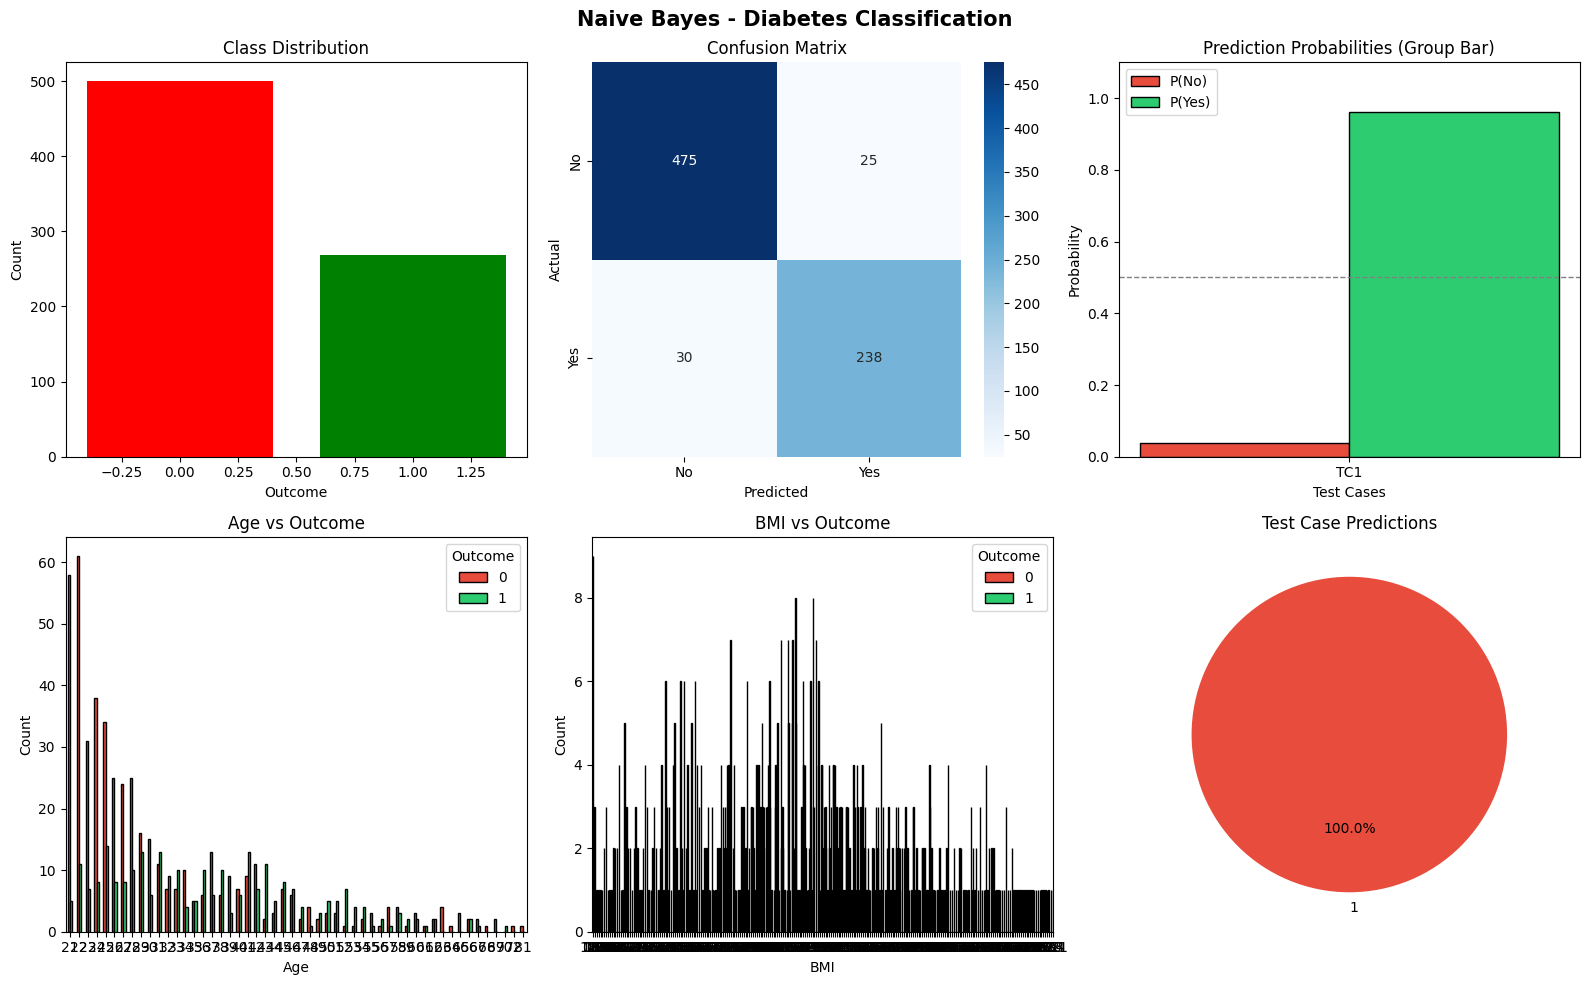

In [22]:
# Pre-calculate variables for the test predictions so the plots work
test_cases = test
probs_no = []
probs_yes = []
predictions = []

for t in test_cases:
    row_data = [[
        le['Pregnancies'].transform([t[0]])[0],
            le['Glucose'].transform([t[1]])[0],
            le['BloodPressure'].transform([t[2]])[0],
            le['SkinThickness'].transform([t[3]])[0],
            le['Insulin'].transform([t[4]])[0],
            le['BMI'].transform([t[5]])[0],
            le['DiabetesPedigreeFunction'].transform([t[6]])[0],
            le['Age'].transform([t[7]])[0]
    ]]
    prob = model.predict_proba(row_data)[0]
    pred = le['Outcome'].inverse_transform(model.predict(row_data))[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])
    predictions.append(pred)

# --Plots------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Naive Bayes - Diabetes Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['Outcome'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['red', 'green'])
axes[0, 0].set_title('Class Distribution')
axes[0, 0].set_xlabel('Outcome')
axes[0, 0].set_ylabel('Count')

# 2. Confusion Matrix
cm = confusion_matrix(Y, model.predict(X))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

# 3. Prediction Probabilities (Group Bar)
tc_lables = [f"TC{i+1}" for i in range(len(test_cases))]
x_pos = np.arange(len(tc_lables))
w = 0.3
axes[0, 2].bar(x_pos - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_pos + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("Prediction Probabilities (Group Bar)")
axes[0, 2].set_xlabel('Test Cases')
axes[0, 2].set_xticks(x_pos)
axes[0, 2].set_xticklabels(tc_lables)
axes[0, 2].set_ylabel('Probability')
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Age vs Outcome
age_counts = df.groupby(['Age', 'Outcome']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 0].set_title('Age vs Outcome')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(title="Outcome")

# 5. BMI vs Outcome
inc_counts = df.groupby(['BMI', 'Outcome']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 1].set_title('BMI vs Outcome')
axes[1, 1].set_xlabel('BMI')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend(title="Outcome")

# 6. Pie Chart - Final Predictions
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.1f%%', startangle=90)
axes[1, 2].set_title('Test Case Predictions')

plt.tight_layout()
plt.show()